In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Online Retail Dataset
df = pd.read_excel("Online Retail.xlsx")

# Show first 5 rows
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:

# Check dataset size
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 541909
Total Columns: 8


In [3]:

# Check missing values in each column
df.isnull().sum()


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [4]:

# Create a clean copy for customer analysis
df_clean = df.dropna(subset=["CustomerID"]).copy()

# Check remaining records
print("Original Rows:", len(df))
print("Cleaned Rows:", len(df_clean))
print("Missing Customer IDs:", df_clean["CustomerID"].isnull().sum())


Original Rows: 541909
Cleaned Rows: 406829
Missing Customer IDs: 0


In [5]:

# Check invalid quantities and prices
print("Negative or Zero Quantity:",
      (df_clean["Quantity"] <= 0).sum())

print("Negative or Zero UnitPrice:",
      (df_clean["UnitPrice"] <= 0).sum())

# Check cancelled invoices
print("Cancelled Invoices:",
      df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())


Negative or Zero Quantity: 8905
Negative or Zero UnitPrice: 40
Cancelled Invoices: 8905


In [6]:

# Keep only valid purchase transactions
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

# Check cleaned dataset
print("Remaining Rows:", len(df_clean))

print("Negative Quantity:",
      (df_clean["Quantity"] <= 0).sum())

print("Invalid Price:",
      (df_clean["UnitPrice"] <= 0).sum())

print("Cancelled Invoices:",
      df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())


Remaining Rows: 397884
Negative Quantity: 0
Invalid Price: 0
Cancelled Invoices: 0


In [7]:

# Calculate total sales for each transaction
df_clean["TotalSales"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Display first 5 rows
df_clean[
    ["InvoiceNo", "CustomerID", "Quantity",
     "UnitPrice", "TotalSales"]
].head()


,InvoiceNo,CustomerID,Quantity,UnitPrice,TotalSales
0,536365,17850.0,6,2.55,15.30
1,536365,17850.0,6,3.39,20.34
2,536365,17850.0,8,2.75,22.00
3,536365,17850.0,6,3.39,20.34
4,536365,17850.0,6,3.39,20.34


In [8]:

# Convert InvoiceDate to datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

# Check date range
print("First Transaction:", df_clean["InvoiceDate"].min())
print("Last Transaction:", df_clean["InvoiceDate"].max())

# Set analysis reference date
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Snapshot Date:", snapshot_date)



First Transaction: 2010-12-01 08:26:00
Last Transaction: 2011-12-09 12:50:00
Snapshot Date: 2011-12-10 12:50:00


In [9]:

# Calculate RFM metrics for each customer
rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalSales", "sum")
).reset_index()

# Display first 5 customers
rfm.head()


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [10]:

# Total unique customers
print("Total Customers:", rfm["CustomerID"].nunique())

# RFM statistical summary
rfm[["Recency", "Frequency", "Monetary"]].describe().round(2)


Total Customers: 4338


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


In [11]:

# Recency: Lower days = Higher score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"],
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: Higher orders = Higher score
rfm["F_Score"] = pd.cut(
    rfm["Frequency"],
    bins=[0, 1, 2, 5, float("inf")],
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: Higher spending = Higher score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"],
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Calculate combined RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"] +
    rfm["F_Score"] +
    rfm["M_Score"]
)

# Display results
rfm.head()


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,4,6
1,12347.0,2,7,4310.00,4,4,4,12
2,12348.0,75,4,1797.24,2,3,4,9
3,12349.0,19,1,1757.55,3,1,4,8
4,12350.0,310,1,334.40,1,1,2,4


In [12]:

# Customer segmentation using RFM scores

conditions = [
    (rfm["R_Score"] >= 3) &
    (rfm["F_Score"] >= 3) &
    (rfm["M_Score"] >= 3),

    (rfm["R_Score"] <= 2) &
    (rfm["M_Score"] == 4),

    (rfm["R_Score"] <= 2) &
    (rfm["F_Score"] >= 3),

    (rfm["R_Score"] >= 2) &
    (rfm["F_Score"] >= 3),

    (rfm["R_Score"] >= 3) &
    (rfm["F_Score"] <= 2),

    (rfm["R_Score"] <= 2) &
    (rfm["F_Score"] <= 2)
]

segments = [
    "Champions",
    "High-Value Inactive",
    "At Risk",
    "Loyal",
    "Recent Occasional",
    "Hibernating"
]

rfm["Segment"] = np.select(
    conditions,
    segments,
    default="Regular"
)

# Count customers in each segment
rfm["Segment"].value_counts()


Segment
Hibernating            1541
Champions              1302
Recent Occasional       739
At Risk                 377
High-Value Inactive     232
Loyal                   147
Name: count, dtype: int64

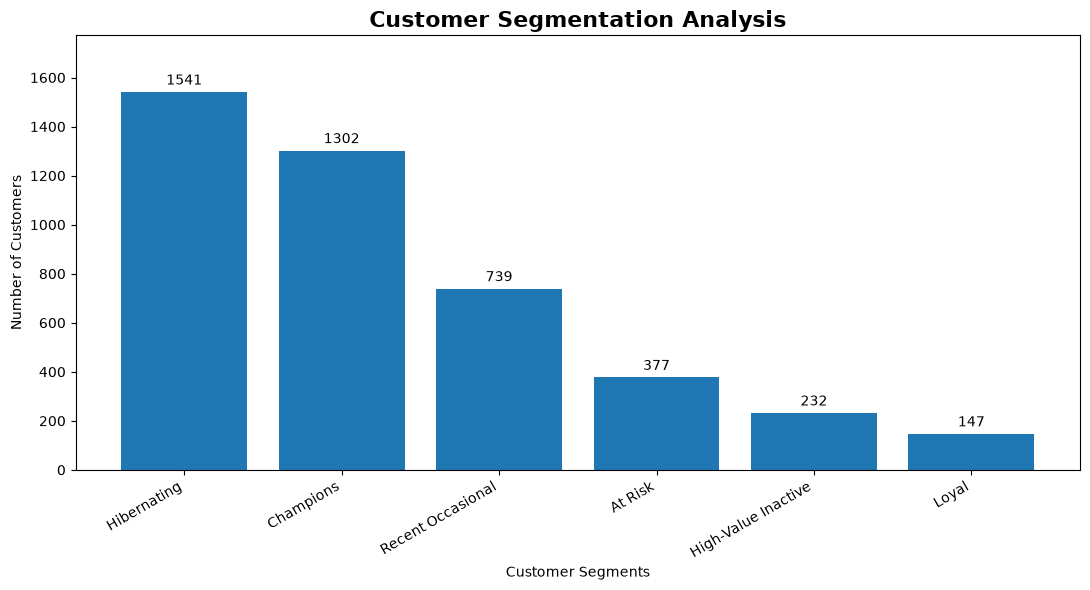

In [13]:

# Customer Segmentation Visualization

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(11, 6))

bars = plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.title(
    "Customer Segmentation Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segments")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30, ha="right")

# Show customer counts above bars
plt.bar_label(bars, padding=3)

plt.ylim(0, segment_counts.max() * 1.15)

plt.tight_layout()
plt.show()



In [15]:

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Select RFM features
rfm_features = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

# Reduce extreme value differences
rfm_log = np.log1p(rfm_features)

# Standardize the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Check the result
print("Dataset Shape:", rfm_scaled.shape)

pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"]
).head().round(2)


Dataset Shape: (4338, 3)


,Recency,Frequency,Monetary
0,1.46,-0.96,3.71
1,-2.04,1.07,1.41
2,0.37,0.39,0.72
3,-0.62,-0.96,0.70
4,1.42,-0.96,-0.62


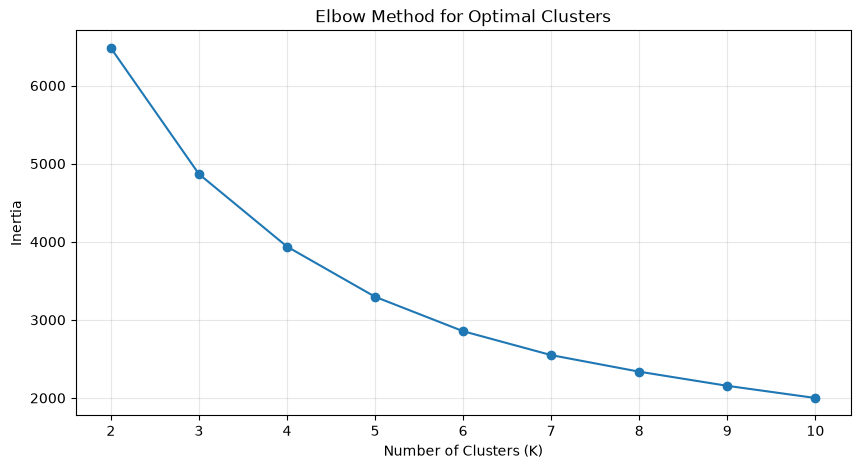

In [16]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Calculate inertia for different clusters
inertia = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(10, 5))

plt.plot(K, inertia, marker="o")

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(list(K))
plt.grid(alpha=0.3)

plt.show()


In [17]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Full Dataset Silhouette Analysis
results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    results.append({
        "Clusters": k,
        "Silhouette_Score": round(score, 4)
    })

# Display results
silhouette_results = pd.DataFrame(results)

print(silhouette_results.to_string(index=False))

# Find highest Silhouette Score
best_row = silhouette_results.loc[
    silhouette_results["Silhouette_Score"].idxmax()
]

print("\nBest K:", int(best_row["Clusters"]))
print("Best Silhouette Score:", best_row["Silhouette_Score"])


 Clusters  Silhouette_Score
        2            0.4329
        3            0.3365
        4            0.3371
        5            0.3161
        6            0.3133
        7            0.3100
        8            0.3008
        9            0.2817
       10            0.2787

Best K: 2
Best Silhouette Score: 0.4329


In [18]:

from sklearn.cluster import KMeans

# Train K-Means with 2 clusters
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign cluster to each customer
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Count customers in each cluster
print("Customers per Cluster:")
print(rfm["Cluster"].value_counts().sort_index())

# Understand cluster behavior
print("\nCluster Profiles:")
print(
    rfm.groupby("Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].median().round(2)
)


Customers per Cluster:
Cluster
0    2671
1    1667
Name: count, dtype: int64

Cluster Profiles:
         Recency  Frequency  Monetary
Cluster                              
0           96.0        1.0    363.88
1           16.0        6.0   2064.95


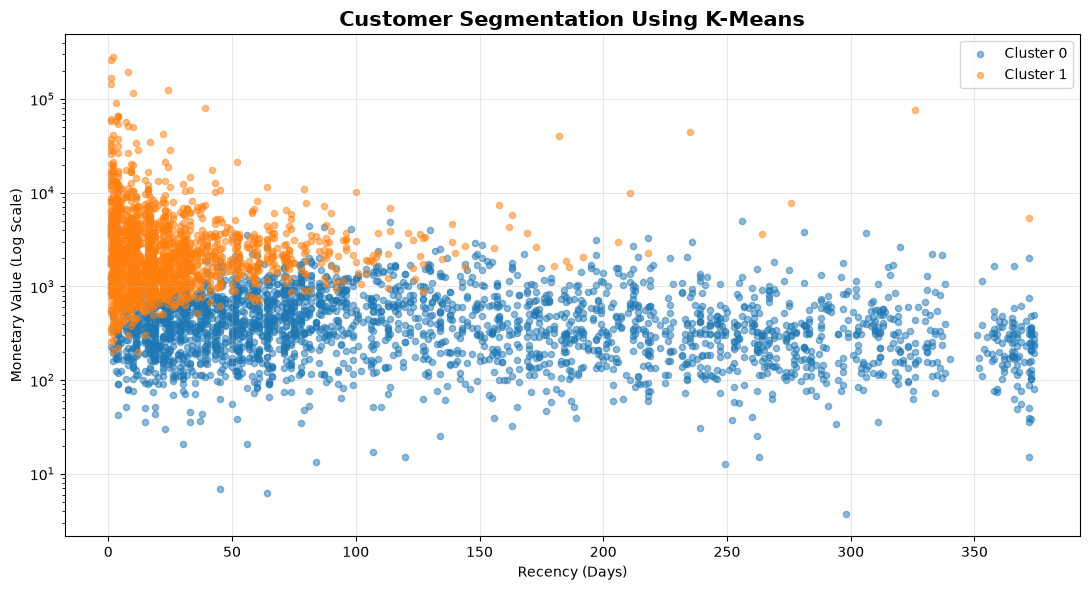

In [19]:

import matplotlib.pyplot as plt

# Visualize K-Means Clusters
plt.figure(figsize=(11, 6))

for cluster_id in sorted(rfm["Cluster"].unique()):
    data = rfm[rfm["Cluster"] == cluster_id]

    plt.scatter(
        data["Recency"],
        data["Monetary"],
        label=f"Cluster {cluster_id}",
        alpha=0.5,
        s=20
    )

plt.title(
    "Customer Segmentation Using K-Means",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (Log Scale)")

plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

from sklearn.cluster import KMeans

# Train an alternative model with 4 clusters
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Keep original 2-cluster results safe
rfm["Cluster_4"] = kmeans_4.fit_predict(rfm_scaled)

# Count customers in each cluster
print("Customers per Cluster:")
print(rfm["Cluster_4"].value_counts().sort_index())

# Analyze each cluster's purchasing behavior
print("\nCluster Profiles:")
print(
    rfm.groupby("Cluster_4")[
        ["Recency", "Frequency", "Monetary"]
    ].median().round(2)
)


Customers per Cluster:
Cluster_4
0     837
1     716
2    1173
3    1612
Name: count, dtype: int64

Cluster Profiles:
           Recency  Frequency  Monetary
Cluster_4                              
0             17.0        2.0    471.70
1              8.0       10.0   3733.87
2             56.0        4.0   1345.62
3            177.0        1.0    298.26


In [21]:

# Assign meaningful names to K-Means clusters
cluster_names = {
    0: "Recent Occasional",
    1: "High-Value Active",
    2: "Established Customers",
    3: "Inactive Low-Spend"
}

rfm["ML_Segment"] = rfm["Cluster_4"].map(cluster_names)

# Export final customer segmentation results
rfm.to_csv("Customer_Segments.csv", index=False)

print("CSV file saved successfully!")

# Check segment distribution
print("\nCustomers per ML Segment:")
print(rfm["ML_Segment"].value_counts())


CSV file saved successfully!

Customers per ML Segment:
ML_Segment
Inactive Low-Spend       1612
Established Customers    1173
Recent Occasional         837
High-Value Active         716
Name: count, dtype: int64


In [22]:

import joblib

# Save trained model and preprocessing settings
model_bundle = {
    "model": kmeans_4,
    "scaler": scaler,
    "features": ["Recency", "Frequency", "Monetary"],
    "transformation": "log1p",
    "cluster_names": cluster_names
}

joblib.dump(
    model_bundle,
    "customer_segmentation_model.joblib"
)

print("Machine Learning model saved successfully!")


Machine Learning model saved successfully!


,ML_Segment,Customers,Total_Revenue,Average_Revenue,Revenue_Share_%
1,High-Value Active,716,5781175.08,8074.27,64.87
0,Established Customers,1173,2114718.42,1802.83,23.73
2,Inactive Low-Spend,1612,553641.45,343.45,6.21
3,Recent Occasional,837,461872.95,551.82,5.18


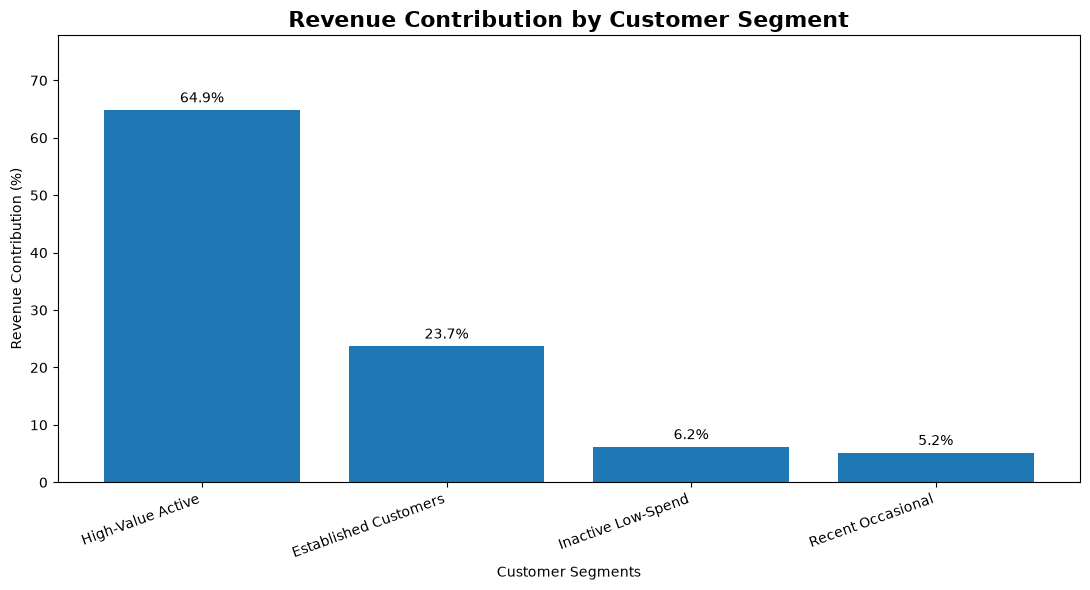

In [23]:

import pandas as pd
import matplotlib.pyplot as plt

# Calculate revenue by customer segment
segment_summary = rfm.groupby("ML_Segment").agg(
    Customers=("CustomerID", "count"),
    Total_Revenue=("Monetary", "sum"),
    Average_Revenue=("Monetary", "mean")
).reset_index()

# Calculate revenue contribution percentage
total_revenue = segment_summary["Total_Revenue"].sum()

segment_summary["Revenue_Share_%"] = (
    segment_summary["Total_Revenue"] / total_revenue * 100
)

# Sort by total revenue
segment_summary = segment_summary.sort_values(
    "Total_Revenue",
    ascending=False
)

# Display summary table
display(segment_summary.round(2))

# Create revenue contribution chart
plt.figure(figsize=(11, 6))

bars = plt.bar(
    segment_summary["ML_Segment"],
    segment_summary["Revenue_Share_%"]
)

plt.title(
    "Revenue Contribution by Customer Segment",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segments")
plt.ylabel("Revenue Contribution (%)")

plt.xticks(rotation=20, ha="right")

plt.bar_label(
    bars,
    fmt="%.1f%%",
    padding=3
)

plt.ylim(
    0,
    segment_summary["Revenue_Share_%"].max() * 1.2
)

plt.tight_layout()
plt.show()


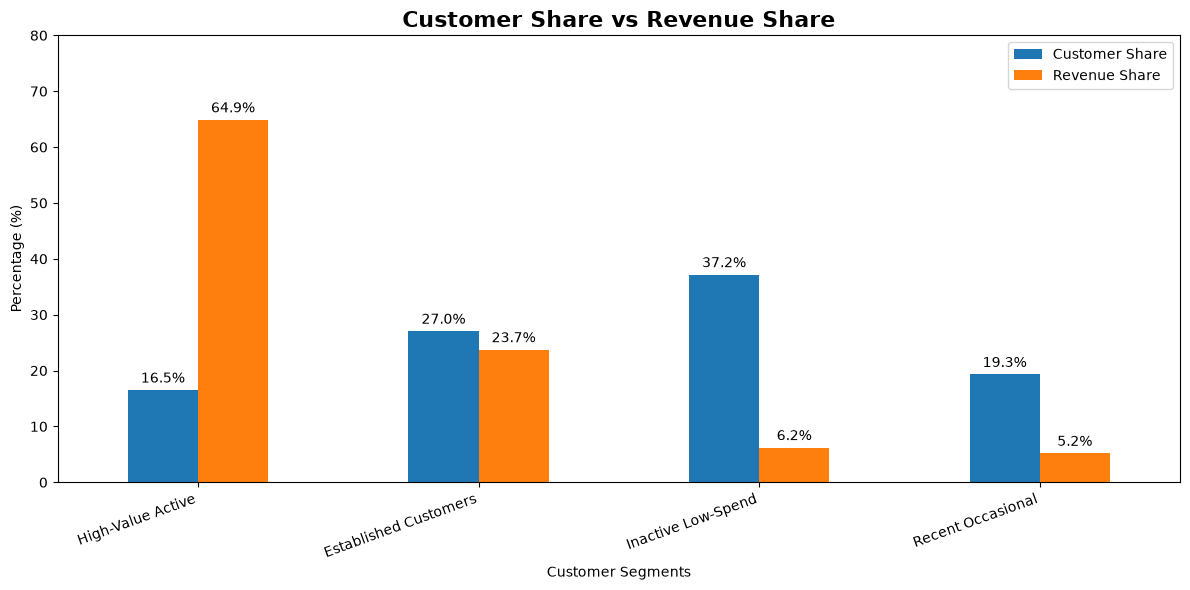

Chart and summary saved successfully!


In [24]:

# Compare customer share and revenue share

segment_summary["Customer_Share_%"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
    * 100
)

# Create comparison chart
ax = segment_summary.plot(
    x="ML_Segment",
    y=["Customer_Share_%", "Revenue_Share_%"],
    kind="bar",
    figsize=(12, 6),
    rot=20
)

plt.title(
    "Customer Share vs Revenue Share",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Customer Segments")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=20, ha="right")
plt.legend(["Customer Share", "Revenue Share"])

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)

plt.ylim(0, 80)
plt.tight_layout()

# Save high-resolution chart
plt.savefig(
    "Customer_vs_Revenue_Share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export business summary
segment_summary.to_csv(
    "Segment_Revenue_Summary.csv",
    index=False
)

print("Chart and summary saved successfully!")


In [25]:

# Business recommendations for customer segments

recommendations = {
    "High-Value Active": "Offer loyalty rewards and VIP benefits",
    "Established Customers": "Encourage repeat purchases with personalized offers",
    "Recent Occasional": "Introduce product recommendations and follow-up campaigns",
    "Inactive Low-Spend": "Test re-engagement campaigns and targeted discounts"
}

# Add recommendations to segment summary
segment_summary["Recommendation"] = (
    segment_summary["ML_Segment"].map(recommendations)
)

# Display business insights
display(
    segment_summary[
        [
            "ML_Segment",
            "Customers",
            "Customer_Share_%",
            "Revenue_Share_%",
            "Recommendation"
        ]
    ].round(2)
)

# Export recommendations
segment_summary.to_csv(
    "Business_Recommendations.csv",
    index=False
)

print("Business recommendations saved successfully!")


,ML_Segment,Customers,Customer_Share_%,Revenue_Share_%,Recommendation
1,High-Value Active,716,16.51,64.87,Offer loyalty rewards and VIP benefits
0,Established Customers,1173,27.04,23.73,Encourage repeat purchases with personalized o...
2,Inactive Low-Spend,1612,37.16,6.21,Test re-engagement campaigns and targeted disc...
3,Recent Occasional,837,19.29,5.18,Introduce product recommendations and follow-u...


Business recommendations saved successfully!


In [26]:

from pathlib import Path

# Final project validation
print("Total Customers:", len(rfm))
print("Unique Customers:", rfm["CustomerID"].nunique())

print("Missing ML Segments:",
      rfm["ML_Segment"].isna().sum())

print("Total Segmented Customers:",
      segment_summary["Customers"].sum())

print("Customer Share Total:",
      round(segment_summary["Customer_Share_%"].sum(), 2))

print("Revenue Share Total:",
      round(segment_summary["Revenue_Share_%"].sum(), 2))

# Check saved project files
files = [
    "Customer_Segments.csv",
    "customer_segmentation_model.joblib",
    "Segment_Revenue_Summary.csv",
    "Customer_vs_Revenue_Share.png",
    "Business_Recommendations.csv"
]

for file in files:
    print(file, ":", "Saved" if Path(file).exists() else "Missing")


Total Customers: 4338
Unique Customers: 4338
Missing ML Segments: 0
Total Segmented Customers: 4338
Customer Share Total: 100.0
Revenue Share Total: 100.0
Customer_Segments.csv : Saved
customer_segmentation_model.joblib : Saved
Segment_Revenue_Summary.csv : Saved
Customer_vs_Revenue_Share.png : Saved
Business_Recommendations.csv : Saved
